In [1]:
# Cell 1: Imports and Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import pyedflib
import os
import random
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler

np.random.seed(1)
random.seed(1)

data_dir = '../data/'

print(" Imports loaded")

 Imports loaded


In [2]:
# Cell 2: Parse all patient summary files
# reads each patient's summary.txt to extract seizure timings
# summary file lists which EDF file each seizure is in and when it starts/ends

def parse_summary_file(patient_id):
    summary_path = os.path.join(data_dir, patient_id, f'{patient_id}-summary.txt')
    
    # if no summary file exists for this patient skip them
    if not os.path.exists(summary_path):
        return []
    
    with open(summary_path, 'r') as f:
        content = f.read()
    
    seizures = []
    current_file = None  # keeps track of which EDF file we are currently reading about
    lines = content.split('\n')
    i = 0
    
    while i < len(lines):
        line = lines[i].strip()
        
        # summary file groups seizures by EDF file
        # example: "File Name: chb01_03.edf"
        if 'File Name:' in line:
            current_file = line.split('File Name:')[-1].strip()
        
        # look for seizure start time lines
        # handles both "Seizure Start Time" and "Seizure 1 Start Time"
        # since different patients use slightly different formats
        if current_file and ('Seizure' in line) and ('Start Time' in line):
            try:
                # extract just the number of seconds from the line
                # "Seizure 1 Start Time: 2996 seconds" -> 2996
                start_part = line.split('Start Time:')[-1].strip()
                start = int(''.join(filter(str.isdigit, start_part.split('seconds')[0])))
                
                # the end time is always on one of the next few lines
                # look ahead up to 5 lines to find it
                for j in range(i+1, min(i+5, len(lines))):
                    next_line = lines[j].strip()
                    if 'End Time' in next_line:
                        end_part = next_line.split('End Time:')[-1].strip()
                        end = int(''.join(filter(str.isdigit, end_part.split('seconds')[0])))
                        
                        # store this seizure as a dictionary with all relevant info
                        seizures.append({
                            'file':    current_file,  # which EDF file contains this seizure
                            'start':   start,          # seizure onset in seconds
                            'end':     end,            # seizure end in seconds
                            'patient': patient_id      # which patient
                        })
                        break
            except:
                pass  # skip any lines that dont parse correctly
        
        i += 1
    
    return seizures

# parse all 23 patients
# chb21 excluded because it is the same  as chb01 recorded 1.5 years later
patient_ids = [f'chb{str(i).zfill(2)}' for i in range(1, 25) if i != 21]

all_patients_seizures = {}

for patient_id in patient_ids:
    seizures = parse_summary_file(patient_id)
    if len(seizures) > 0:
        # only keep patients that have at least one seizure
        all_patients_seizures[patient_id] = seizures


In [3]:
# Cell 3: Feature extraction functions — 69 features (3 × 23 channels)

sfreq = 256

# standard channel names used across all CHB-MIT patients
standard_channels = [
    'FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1',
    'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2',
    'FP2-F8', 'F8-T8', 'T8-P8', 'P8-O2',
    'FZ-CZ',  'CZ-PZ', 'P7-T7', 'T7-FT9',
    'FT9-FT10', 'FT10-T8', 'T8-P8'
]

# Read summary file  to get valid channel indices and names for a patient
# Only reads the first channel since some summary files later on change the name of the channel (irrelvenat)
# Skip channels labeled "-" that contain no real data

def get_patient_channels(patient_id):
    summary_path = os.path.join(data_dir, patient_id, f'{patient_id}-summary.txt')
    valid_channels = []
    found_channels = False
    with open(summary_path, 'r', errors='ignore') as f:
        lines = f.readlines()
    for line in lines:
        line = line.strip()
        # this line marks the start of the channel list in the summary file
        if 'Channels in EDF' in line:
            found_channels = True
            continue

        # once hit the first file entry stop reading channels
        # prevents from reading channel updates
        # stop here as not read channel changes listed later
        if found_channels and line.startswith('File Name:'):
            break

        # read lines that look like "Channel 1: FP-FP7"
        # grab each channel line number and name
        if found_channels and line.startswith('Channel ') and ':' in line:
            parts = line.split(':')
            if len(parts) >= 2:
                try:
                    ch_name = parts[1].strip()
                    ch_idx = int(parts[0].replace('Channel', '').strip()) - 1
                    # skip EEG channels with no name: theyr pretty useless
                    if ch_name != '-' and ch_name != '':
                        valid_channels.append((ch_idx, ch_name))
                except ValueError:
                    continue
    # returns a tuple of all the valid channels for a patient
    return valid_channels


# Opens an EDF file and reads one channel of raw EEG voltage data
# EDF is the standard file format of the CHB mit dataset
# reutnrs an array of voltage values
def extract_eeg_from_file(patient_id, filename, channel_idx):
    filepath = os.path.join(data_dir, patient_id, filename)
    f = pyedflib.EdfReader(filepath)
    # skip if theres a channel missing
    if channel_idx >= f.signals_in_file:
        f.close()
        return None
    sig = f.readSignal(channel_idx)
    f.close()
    return sig

def calculate_entropy(seg):
    # count how many samples fall in each of 50 voltage bins
    hist, _ = np.histogram(seg, bins=50)
    # convert counts to probabilities (must sum to 1)
    hist = hist / np.sum(hist)
    # remove empty bins to avoid log(0) which is undefined
    hist = hist[hist > 0]
    # Shannon entropy formula
    return -np.sum(hist * np.log2(hist))

def calculate_line_length(seg):
    # difference between each sample and the next one
    differences = np.diff(seg)
    # take absolute value
    absolute_differences = np.abs(differences)
    # sum everything up to get total signal variation
    return np.sum(absolute_differences)

def calculate_high_freq_power(seg, sfreq=256):
    # nperseg is the chunk size for Welch's method
    # cap at 1024 samples to keep computation fast
    nperseg = min(1024, len(seg))
    # f = frequency array, pxx = power at each frequency
    f, pxx = signal.welch(seg, sfreq, nperseg=nperseg)
    # add up all power at 20 Hz and above
    return np.sum(pxx[f >= 20])

def extract_features_from_window(eeg_channels, channel_info, start_sec, end_sec, sfreq):
    """
    This is the main feature extraction function.
    
    For one 2-minute window of EEG it:
    1. Loops through all 23 standard channels
    2. Extracts entropy, line length, and high-freq power from each channel
    3. Returns one array of 69 numbers (3 features × 23 channels)
    
    If a channel is missing for this patient it fills with 0
    so the output is always exactly 69 numbers regardless of patient.
    
    This 69-number array becomes one row in the X matrix.
    """
    # build a dictionary so we can look up channels by name
    # maps channel_name -> raw EEG signal array
    channel_lookup = {}
    for i, (ch_idx, ch_name) in enumerate(channel_info):
        if i < len(eeg_channels) and eeg_channels[i] is not None:
            channel_lookup[ch_name] = eeg_channels[i]

    # convert window start/end from seconds to sample numbers
    # at 256 Hz, 1 second = 256 samples, 2 minutes = 30,720 samples
    start_idx = int(start_sec * sfreq)
    end_idx   = int(end_sec   * sfreq)

    feature_vector = [] # will hold 69 numbers when done
    feature_names  = [] # will hold names like FP-F7: entropy


    # loop through all 23 channels in fixed order
    for ch_name in standard_channels:
        if ch_name in channel_lookup:
            sig = channel_lookup[ch_name]
            # slice out just the 2-minute segment 
            seg = sig[start_idx:end_idx]
            if len(seg) > 0:
                # calculate all 3 features for this channel
                feature_vector.extend([
                    calculate_entropy(seg),
                    calculate_line_length(seg),
                    calculate_high_freq_power(seg, sfreq),
                ])
            else:
                # segnment is empty
                feature_vector.extend([0, 0, 0])
        else:
            # channel doesn't exist for the patient
            feature_vector.extend([0, 0, 0])

        # store the name of each feature
        feature_names.extend([
            f'{ch_name}_entropy',
            f'{ch_name}_line_length',
            f'{ch_name}_hf_power',
        ])

    # return numpy array
    return np.array(feature_vector), feature_names

def get_previous_file(patient_id, current_file):
    """
    This function finds the file that came right before the current one.
    
    Example: chb01_03.edf -> returns chb01_02.edf
    Returns None if there is no previous file.
    """
    patient_dir = os.path.join(data_dir, patient_id)
    all_files = sorted([f for f in os.listdir(patient_dir) if f.endswith('.edf')])
    if current_file not in all_files:
        return None
    idx = all_files.index(current_file)
    return all_files[idx-1] if idx > 0 else None

def load_stitched_preictal(patient_id, sz_file, sz_start, preictal_sec, sfreq, channel_info):
    """
    Loads the full preictal zone (20 minutes) before a seizure.
    
    Stitch the previous file onto the beginning.
    Take the last (1200 - 327 = 873) seconds from the previous file
    and join it with the 327 seconds from the current file.
    This gives us a continuous 1200-second signal ending at seizure onset.
    
    CHB-MIT files are sequential recordings with
    gaps of less than 10 seconds between files.
    
    Returns the stitched EEG data and the time range to extract windows from.
    """
    need_from_prev = preictal_sec - sz_start
    eeg_channels = []
    for ch_idx, ch_name in channel_info:
        try:
            # step 1: load the seizure file
            eeg_current = extract_eeg_from_file(patient_id, sz_file, ch_idx)
            if eeg_current is None:
                eeg_channels.append(None)
                continue

            # step 2: cut off everything at and after the seizure onset
            eeg_current = eeg_current[:int(sz_start * sfreq)]
            if need_from_prev > 0:
                # step 3: need more data so load the previous file
                prev_file = get_previous_file(patient_id, sz_file)
                if prev_file:
                    eeg_prev = extract_eeg_from_file(patient_id, prev_file, ch_idx)
                    if eeg_prev is not None:
                        eeg_channels.append(np.concatenate([
                            eeg_prev[-int(need_from_prev*sfreq):],
                            eeg_current
                        ]))
                    else:
                        # previous file failed to load
                        eeg_channels.append(eeg_current)
                else:
                    # no previous file exists
                    eeg_channels.append(eeg_current)
            else:
                # no stiching needed
                eeg_channels.append(eeg_current)
        except:
            eeg_channels.append(None)

    # return the stitched channels and where to extract windows from
    if need_from_prev > 0:
        return eeg_channels, 0, preictal_sec
    else:
        return eeg_channels, sz_start - preictal_sec, sz_start

print(f"  Features per window: 3 × 23 = {3*23}")

  Features per window: 3 × 23 = 69


In [4]:
# Cell 4: Patient-specific Random Forest with 1-hour gap rule for interictal sampling

WINDOW_SEC   = 120
STEP_SEC     = 120
PREICTAL_SEC = 1200  # 20 minutes before seizure

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler



# randomly select 5 patients
import random
random.seed(99)
all_patient_ids = list(all_patients_seizures.keys())
selected_patients = random.sample(all_patient_ids, 5)
print(f"Selected patients: {selected_patients}")

# use only selected patients
all_patients_seizures_to_use = {
    k: v for k, v in all_patients_seizures.items()
    if k in selected_patients
}

def is_file_safe(patient_id, clean_file, seizure_files_set, all_files, min_gap_files=1):
    """
    Check if a clean file is at least min_gap_files away from any seizure file.
    Since files are sequential and ~1 hour each, 1 file gap ≈ 1 hour gap.
    """
    if clean_file not in all_files:
        return False
    clean_idx = all_files.index(clean_file)
    for sz_file in seizure_files_set:
        if sz_file not in all_files:
            continue
        sz_idx = all_files.index(sz_file)
        if abs(clean_idx - sz_idx) <= min_gap_files:
            return False
    return True

all_results = {}
feature_names_list = None

print("Running patient-specific Random Forest (with 1-hour gap rule)...\n")
print(f"{'Patient':<12} {'Seizures':>10} {'Windows':>10} {'Sensitivity':>13} {'Specificity':>13} {'AUC':>8}")

for patient_id, seizures in all_patients_seizures_to_use.items():
    
    patient_dir   = os.path.join(data_dir, patient_id)
    channel_info  = get_patient_channels(patient_id)
    all_edf       = sorted([f for f in os.listdir(patient_dir) if f.endswith('.edf')])
    seizure_files = set([sz['file'] for sz in seizures])
    
    # only use clean files that are at least 1 file away from any seizure file
    clean_files = [f for f in all_edf 
                   if f not in seizure_files 
                   and is_file_safe(patient_id, f, seizure_files, all_edf, min_gap_files=1)]
    
    if len(clean_files) == 0:
        print(f"{patient_id:<12} SKIPPED: no clean files with 1-hour gap")
        continue
    
    X_pat     = []
    y_pat     = []
    sz_groups = []
    
    # ── PREICTAL WINDOWS ──────────────────────────────────────────
    valid_sz_idx = 0
    for sz in seizures:
        sz_start = sz['start']
        sz_file  = sz['file']
        
        eeg_channels, extract_start, extract_end = load_stitched_preictal(
            patient_id, sz_file, sz_start, PREICTAL_SEC, sfreq, channel_info
        )
        
        if extract_end - extract_start < WINDOW_SEC:
            continue
        
        current_time = extract_start
        while current_time + WINDOW_SEC <= extract_end:
            fv, fn = extract_features_from_window(
                eeg_channels, channel_info,
                current_time, current_time + WINDOW_SEC, sfreq
            )
            X_pat.append(fv)
            y_pat.append(1)
            sz_groups.append(valid_sz_idx)
            current_time += STEP_SEC
        
        valid_sz_idx += 1
    
    if valid_sz_idx < 2:
        print(f"{patient_id:<12} SKIPPED: fewer than 2 valid seizures")
        continue
    
    preictal_count = len(X_pat)
    
    # ── INTERICTAL WINDOWS ────────────────────────────────────────
    random.seed(1)
    
    possible = []
    for cf in clean_files:
        try:
            fp  = os.path.join(patient_dir, cf)
            f   = pyedflib.EdfReader(fp)
            dur = f.getNSamples()[0] / sfreq
            f.close()
            starts = list(range(0, int(dur - WINDOW_SEC), WINDOW_SEC))
            for s in starts:
                possible.append((cf, s))
        except:
            continue
    
    if len(possible) == 0:
        print(f"{patient_id:<12} SKIPPED: no interictal windows available")
        continue
    
    n_sample = min(preictal_count, len(possible))
    sampled  = random.sample(possible, n_sample)
    
    for i, (cf, start) in enumerate(sampled):
        eeg_ch = []
        for ch_idx, ch_name in channel_info:
            try:
                eeg_ch.append(extract_eeg_from_file(patient_id, cf, ch_idx))
            except:
                eeg_ch.append(None)
        
        fv, _ = extract_features_from_window(
            eeg_ch, channel_info, start, start + WINDOW_SEC, sfreq
        )
        X_pat.append(fv)
        y_pat.append(0)
        sz_groups.append(i % valid_sz_idx)
        del eeg_ch
    
    X_pat = np.nan_to_num(np.array(X_pat), nan=0.0, posinf=0.0, neginf=0.0)
    y_pat = np.array(y_pat)
    sz_groups = np.array(sz_groups)

    # Step 1: z-score normalize per feature for this patient
    # converts each feature to mean=0 std=1
    # so line length (200,000 µV) and entropy (4.5 bits) are on same scale
    X_normalized = X_pat.copy().astype(float)
    mean_pat = X_normalized.mean(axis=0)
    std_pat  = X_normalized.std(axis=0)
    std_pat[std_pat == 0] = 1  # avoid division by zero
    X_normalized = (X_normalized - mean_pat) / std_pat

    # Step 2: global StandardScaler on top
    scaler   = StandardScaler()
    X_scaled = scaler.fit_transform(X_normalized)
    
    rf = RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=1,
        n_jobs=-1
    )
    
    logo = LeaveOneGroupOut()
    
    try:
        y_prob = cross_val_predict(
        rf, X_scaled, y_pat,
        groups=sz_groups,
        cv=logo,
        method='predict_proba'  # <- returns probabilities not binary
    
        )

        y_pred = (y_prob[:, 1] >= 0.5).astype(int)

        
        cm = confusion_matrix(y_pat, y_pred)
        if cm.shape == (2, 2):
            tn, fp, fn, tp = cm.ravel()
            sens = tp / (tp + fn) if (tp + fn) > 0 else 0
            spec = tn / (tn + fp) if (tn + fp) > 0 else 0
            try:
                auc = roc_auc_score(y_pat, y_prob[:, 1])
            except:
                auc = 0
        else:
            sens = spec = auc = 0
        
        all_results[patient_id] = {
            'sensitivity': sens,
            'specificity': spec,
            'auc':         auc,
            'n_seizures':  valid_sz_idx,
            'n_windows':   len(y_pat)
        }
        
        print(f"{patient_id:<12} {valid_sz_idx:>10} {len(y_pat):>10} "
              f"{sens:>12.1%} {spec:>12.1%} {auc:>8.3f}")
    
    except Exception as e:
        print(f"{patient_id:<12} ERROR: {e}")
        continue

avg_sens = np.mean([v['sensitivity'] for v in all_results.values()])
avg_spec = np.mean([v['specificity'] for v in all_results.values()])
avg_auc  = np.mean([v['auc'] for v in all_results.values()])
print(f"{'Mean':<12} {'':>10} {'':>10} {avg_sens:>12.1%} {avg_spec:>12.1%} {avg_auc:>8.3f}")
print(f"\n✓ {len(all_results)} patients completed")

Selected patients: ['chb13', 'chb07', 'chb20', 'chb06', 'chb08']
Running patient-specific Random Forest (with 1-hour gap rule)...

Patient        Seizures    Windows   Sensitivity   Specificity      AUC
chb06                10        200        54.0%        82.0%    0.732
chb07                 3         60        30.0%        73.3%    0.612
chb08                 5        100        90.0%        80.0%    0.866
chb13                12        240        90.0%        98.3%    0.975
chb20                 8        160        97.5%        95.0%    0.990
Mean                                      72.3%        85.7%    0.835

✓ 5 patients completed


In [5]:
thresholds_to_test = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
for t in thresholds_to_test:
    y_pred_t = (y_prob[:, 1] >= t).astype(int)
    cm_t = confusion_matrix(y_pat, y_pred_t)
    sens_t = cm_t[1][1] / (cm_t[1][1] + cm_t[1][0])
    spec_t = cm_t[0][0] / (cm_t[0][0] + cm_t[0][1])
    print(f"Threshold {t}: Sensitivity {sens_t:.1%}, Specificity {spec_t:.1%}")

Threshold 0.2: Sensitivity 98.8%, Specificity 90.0%
Threshold 0.3: Sensitivity 98.8%, Specificity 91.2%
Threshold 0.4: Sensitivity 98.8%, Specificity 95.0%
Threshold 0.5: Sensitivity 97.5%, Specificity 95.0%
Threshold 0.6: Sensitivity 96.2%, Specificity 95.0%
Threshold 0.7: Sensitivity 93.8%, Specificity 98.8%


Testing different tree counts...

   Trees   Sensitivity   Specificity      AUC
---------------------------------------------
      50        97.5%        95.0%    0.990
     100        98.8%        95.0%    0.989
     150        97.5%        95.0%    0.991
     200        97.5%        95.0%    0.990
     250        97.5%        95.0%    0.990
     300        97.5%        95.0%    0.989
     400        97.5%        95.0%    0.989
     500        97.5%        95.0%    0.988


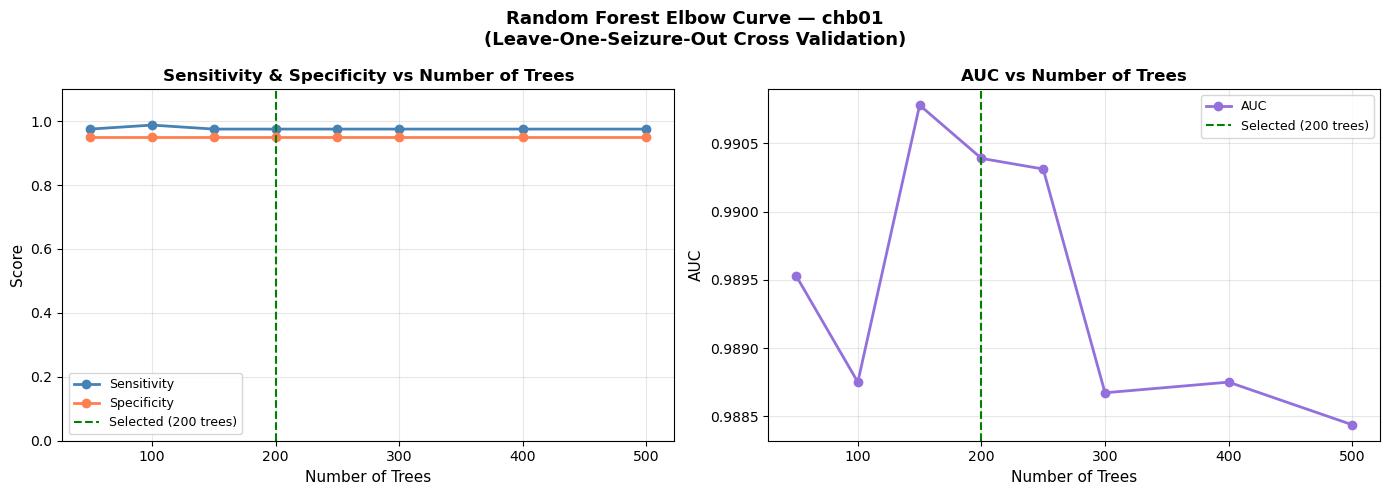

In [6]:
# Elbow curve — sensitivity and specificity vs number of trees
# using chb01 as test patient

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score

# use chb01 data — rerun feature extraction for chb01 only
# assumes X_pat, y_pat, sz_groups are still defined from last patient loop run
# if not — rerun cell 4 with only chb01

tree_counts = [50, 100, 150, 200, 250, 300, 400, 500]
results_trees = []

print(f"Testing different tree counts...\n")
print(f"{'Trees':>8} {'Sensitivity':>13} {'Specificity':>13} {'AUC':>8}")
print("-" * 45)

for n_trees in tree_counts:
    rf_test = RandomForestClassifier(
        n_estimators=n_trees,
        class_weight='balanced',
        random_state=1,
        n_jobs=-1
    )
    
    logo = LeaveOneGroupOut()
    
    y_prob_t = cross_val_predict(
        rf_test, X_scaled, y_pat,
        groups=sz_groups,
        cv=logo,
        method='predict_proba'
    )
    y_pred_t = (y_prob_t[:, 1] >= 0.5).astype(int)
    
    cm_t = confusion_matrix(y_pat, y_pred_t)
    if cm_t.shape == (2, 2):
        tn, fp, fn, tp = cm_t.ravel()
        sens = tp / (tp + fn) if (tp + fn) > 0 else 0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        auc  = roc_auc_score(y_pat, y_prob_t[:, 1])
    else:
        sens = spec = auc = 0
    
    results_trees.append({
        'trees':       n_trees,
        'sensitivity': sens,
        'specificity': spec,
        'auc':         auc
    })
    
    print(f"{n_trees:>8} {sens:>12.1%} {spec:>12.1%} {auc:>8.3f}")

# plot elbow curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

trees      = [r['trees']       for r in results_trees]
sens_vals  = [r['sensitivity'] for r in results_trees]
spec_vals  = [r['specificity'] for r in results_trees]
auc_vals   = [r['auc']         for r in results_trees]

# left: sensitivity and specificity vs trees
axes[0].plot(trees, sens_vals, color='steelblue', 
             linewidth=2, marker='o', label='Sensitivity')
axes[0].plot(trees, spec_vals, color='coral',
             linewidth=2, marker='o', label='Specificity')
axes[0].axvline(200, color='green', linewidth=1.5,
                linestyle='--', label='Selected (200 trees)')
axes[0].set_xlabel('Number of Trees', fontsize=11)
axes[0].set_ylabel('Score', fontsize=11)
axes[0].set_title('Sensitivity & Specificity vs Number of Trees',
                  fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(0, 1.1)

# right: AUC vs trees
axes[1].plot(trees, auc_vals, color='mediumpurple',
             linewidth=2, marker='o', label='AUC')
axes[1].axvline(200, color='green', linewidth=1.5,
                linestyle='--', label='Selected (200 trees)')
axes[1].set_xlabel('Number of Trees', fontsize=11)
axes[1].set_ylabel('AUC', fontsize=11)
axes[1].set_title('AUC vs Number of Trees', fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Random Forest Elbow Curve — chb01\n'
             '(Leave-One-Seizure-Out Cross Validation)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('elbow_curve_trees.png', dpi=300, bbox_inches='tight')
plt.show()

Running elbow curve across 5 patients...

Processing chb13...
  ✓ Done
Processing chb07...
  ✓ Done
Processing chb20...
  ✓ Done
Processing chb06...
  ✓ Done
Processing chb08...
  ✓ Done

Mean results across 5 patients:
   Trees   Sensitivity   Specificity      AUC
---------------------------------------------
      50        71.6%        86.3%    0.826
     100        72.5%        85.8%    0.831
     150        72.3%        86.2%    0.833
     200        72.3%        85.7%    0.835
     250        72.3%        85.6%    0.838
     300        72.3%        87.1%    0.838
     400        72.7%        86.2%    0.838
     500        73.5%        86.8%    0.838


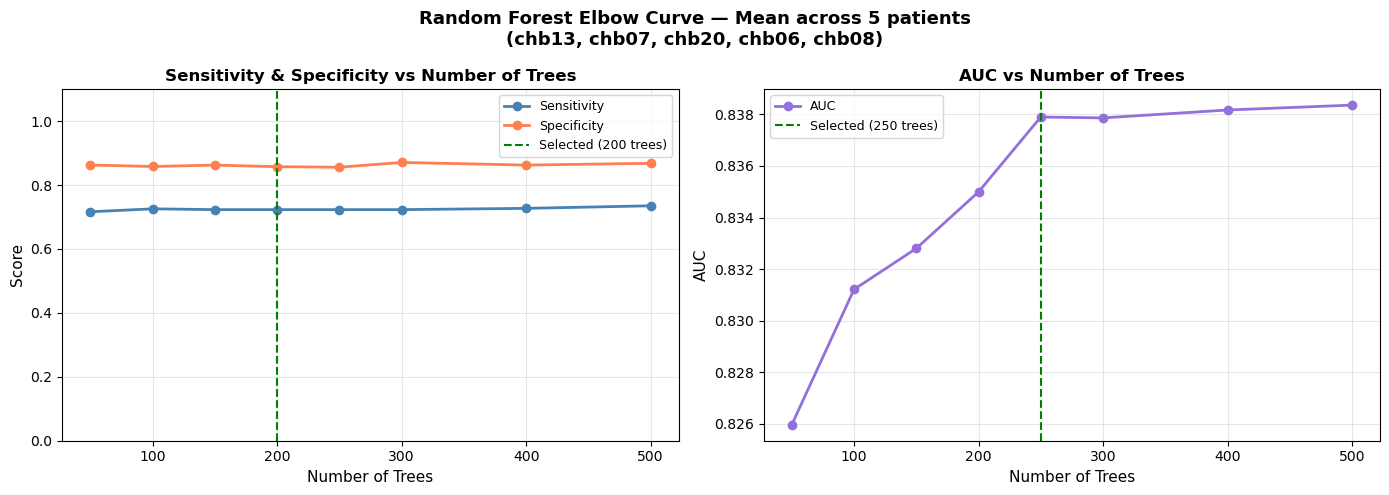

In [7]:
# Elbow curve — averaged across 5 subset patients

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler

tree_counts = [50, 100, 150, 200, 250, 300, 400, 500]
selected_patients = ['chb13', 'chb07', 'chb20', 'chb06', 'chb08']

# store results per patient per tree count
all_patient_results = {n: [] for n in tree_counts}

print("Running elbow curve across 5 patients...\n")

for patient_id in selected_patients:
    print(f"Processing {patient_id}...")
    
    seizures     = all_patients_seizures[patient_id]
    channel_info = get_patient_channels(patient_id)
    patient_dir  = os.path.join(data_dir, patient_id)
    all_edf      = sorted([f for f in os.listdir(patient_dir) if f.endswith('.edf')])
    seizure_files = set([sz['file'] for sz in seizures])
    clean_files  = [f for f in all_edf
                    if f not in seizure_files
                    and is_file_safe(patient_id, f, seizure_files, all_edf, min_gap_files=1)]
    
    if len(clean_files) == 0:
        print(f"  ✗ No clean files — skipping")
        continue
    
    X_pat     = []
    y_pat     = []
    sz_groups = []
    valid_sz_idx = 0
    
    # preictal windows
    for sz in seizures:
        sz_start = sz['start']
        sz_file  = sz['file']
        eeg_channels, extract_start, extract_end = load_stitched_preictal(
            patient_id, sz_file, sz_start, PREICTAL_SEC, sfreq, channel_info
        )
        if extract_end - extract_start < WINDOW_SEC:
            continue
        current_time = extract_start
        while current_time + WINDOW_SEC <= extract_end:
            fv, fn = extract_features_from_window(
                eeg_channels, channel_info,
                current_time, current_time + WINDOW_SEC, sfreq
            )
            X_pat.append(fv)
            y_pat.append(1)
            sz_groups.append(valid_sz_idx)
            current_time += STEP_SEC
        valid_sz_idx += 1
    
    if valid_sz_idx < 2:
        print(f"  ✗ Fewer than 2 valid seizures — skipping")
        continue
    
    preictal_count = len(X_pat)
    
    # interictal windows
    random.seed(1)
    possible = []
    for cf in clean_files:
        try:
            fp  = os.path.join(patient_dir, cf)
            f   = pyedflib.EdfReader(fp)
            dur = f.getNSamples()[0] / sfreq
            f.close()
            starts = list(range(0, int(dur - WINDOW_SEC), WINDOW_SEC))
            for s in starts:
                possible.append((cf, s))
        except:
            continue
    
    n_sample = min(preictal_count, len(possible))
    if n_sample == 0:
        continue
    sampled = random.sample(possible, n_sample)
    
    for i, (cf, start) in enumerate(sampled):
        eeg_ch = []
        for ch_idx, ch_name in channel_info:
            try:
                eeg_ch.append(extract_eeg_from_file(patient_id, cf, ch_idx))
            except:
                eeg_ch.append(None)
        fv, _ = extract_features_from_window(
            eeg_ch, channel_info, start, start + WINDOW_SEC, sfreq
        )
        X_pat.append(fv)
        y_pat.append(0)
        sz_groups.append(i % valid_sz_idx)
        del eeg_ch
    
    X_pat     = np.nan_to_num(np.array(X_pat), nan=0.0, posinf=0.0, neginf=0.0)
    y_pat     = np.array(y_pat)
    sz_groups = np.array(sz_groups)
    
    # normalize
    X_normalized = X_pat.copy().astype(float)
    mean_pat = X_normalized.mean(axis=0)
    std_pat  = X_normalized.std(axis=0)
    std_pat[std_pat == 0] = 1
    X_normalized = (X_normalized - mean_pat) / std_pat
    scaler   = StandardScaler()
    X_scaled = scaler.fit_transform(X_normalized)
    
    logo = LeaveOneGroupOut()
    
    # test each tree count for this patient
    for n_trees in tree_counts:
        rf_test = RandomForestClassifier(
            n_estimators=n_trees,
            class_weight='balanced',
            random_state=1,
            n_jobs=-1
        )
        try:
            y_prob_t = cross_val_predict(
                rf_test, X_scaled, y_pat,
                groups=sz_groups,
                cv=logo,
                method='predict_proba'
            )
            y_pred_t = (y_prob_t[:, 1] >= 0.5).astype(int)
            cm_t = confusion_matrix(y_pat, y_pred_t)
            if cm_t.shape == (2, 2):
                tn, fp, fn, tp = cm_t.ravel()
                sens = tp / (tp + fn) if (tp + fn) > 0 else 0
                spec = tn / (tn + fp) if (tn + fp) > 0 else 0
                auc  = roc_auc_score(y_pat, y_prob_t[:, 1])
                all_patient_results[n_trees].append({
                    'sensitivity': sens,
                    'specificity': spec,
                    'auc':         auc
                })
        except Exception as e:
            print(f"  {patient_id} {n_trees} trees: ERROR {e}")
    
    print(f"  ✓ Done")

# compute mean across patients for each tree count
print("\nMean results across 5 patients:")
print(f"{'Trees':>8} {'Sensitivity':>13} {'Specificity':>13} {'AUC':>8}")
print("-" * 45)

trees_list = []
sens_list  = []
spec_list  = []
auc_list   = []

for n_trees in tree_counts:
    results = all_patient_results[n_trees]
    if len(results) == 0:
        continue
    mean_sens = np.mean([r['sensitivity'] for r in results])
    mean_spec = np.mean([r['specificity'] for r in results])
    mean_auc  = np.mean([r['auc']         for r in results])
    
    trees_list.append(n_trees)
    sens_list.append(mean_sens)
    spec_list.append(mean_spec)
    auc_list.append(mean_auc)
    
    print(f"{n_trees:>8} {mean_sens:>12.1%} {mean_spec:>12.1%} {mean_auc:>8.3f}")

# plot elbow curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(trees_list, sens_list, color='steelblue',
             linewidth=2, marker='o', label='Sensitivity')
axes[0].plot(trees_list, spec_list, color='coral',
             linewidth=2, marker='o', label='Specificity')
axes[0].axvline(200, color='green', linewidth=1.5,
                linestyle='--', label='Selected (200 trees)')
axes[0].set_xlabel('Number of Trees', fontsize=11)
axes[0].set_ylabel('Score', fontsize=11)
axes[0].set_title('Sensitivity & Specificity vs Number of Trees',
                  fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(0, 1.1)

axes[1].plot(trees_list, auc_list, color='mediumpurple',
             linewidth=2, marker='o', label='AUC')
axes[1].axvline(250, color='green', linewidth=1.5,
                linestyle='--', label='Selected (250 trees)')
axes[1].set_xlabel('Number of Trees', fontsize=11)
axes[1].set_ylabel('AUC', fontsize=11)
axes[1].set_title('AUC vs Number of Trees', fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Random Forest Elbow Curve — Mean across 5 patients\n'
             '(chb13, chb07, chb20, chb06, chb08)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('elbow_curve_5patients.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# Threshold analysis for chb01 only

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler

patient_id = 'chb01'
seizures   = all_patients_seizures[patient_id]
channel_info = get_patient_channels(patient_id)
patient_dir  = os.path.join(data_dir, patient_id)
all_edf      = sorted([f for f in os.listdir(patient_dir) if f.endswith('.edf')])
seizure_files = set([sz['file'] for sz in seizures])
clean_files  = [f for f in all_edf
                if f not in seizure_files
                and is_file_safe(patient_id, f, seizure_files, all_edf, min_gap_files=1)]

X_pat     = []
y_pat     = []
sz_groups = []
valid_sz_idx = 0

# preictal windows
for sz in seizures:
    sz_start = sz['start']
    sz_file  = sz['file']
    eeg_channels, extract_start, extract_end = load_stitched_preictal(
        patient_id, sz_file, sz_start, PREICTAL_SEC, sfreq, channel_info
    )
    if extract_end - extract_start < WINDOW_SEC:
        continue
    current_time = extract_start
    while current_time + WINDOW_SEC <= extract_end:
        fv, fn = extract_features_from_window(
            eeg_channels, channel_info,
            current_time, current_time + WINDOW_SEC, sfreq
        )
        X_pat.append(fv)
        y_pat.append(1)
        sz_groups.append(valid_sz_idx)
        current_time += STEP_SEC
    valid_sz_idx += 1

# interictal windows
random.seed(1)
possible = []
for cf in clean_files:
    try:
        fp  = os.path.join(patient_dir, cf)
        f   = pyedflib.EdfReader(fp)
        dur = f.getNSamples()[0] / sfreq
        f.close()
        starts = list(range(0, int(dur - WINDOW_SEC), WINDOW_SEC))
        for s in starts:
            possible.append((cf, s))
    except:
        continue

n_sample = min(len(X_pat), len(possible))
sampled  = random.sample(possible, n_sample)

for i, (cf, start) in enumerate(sampled):
    eeg_ch = []
    for ch_idx, ch_name in channel_info:
        try:
            eeg_ch.append(extract_eeg_from_file(patient_id, cf, ch_idx))
        except:
            eeg_ch.append(None)
    fv, _ = extract_features_from_window(
        eeg_ch, channel_info, start, start + WINDOW_SEC, sfreq
    )
    X_pat.append(fv)
    y_pat.append(0)
    sz_groups.append(i % valid_sz_idx)
    del eeg_ch

X_pat     = np.nan_to_num(np.array(X_pat), nan=0.0, posinf=0.0, neginf=0.0)
y_pat     = np.array(y_pat)
sz_groups = np.array(sz_groups)

# normalize
X_normalized = X_pat.copy().astype(float)
mean_pat = X_normalized.mean(axis=0)
std_pat  = X_normalized.std(axis=0)
std_pat[std_pat == 0] = 1
X_normalized = (X_normalized - mean_pat) / std_pat
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_normalized)

# train model
rf = RandomForestClassifier(
    n_estimators=250,
    class_weight='balanced',
    random_state=1,
    n_jobs=-1
)

logo = LeaveOneGroupOut()
y_prob = cross_val_predict(
    rf, X_scaled, y_pat,
    groups=sz_groups,
    cv=logo,
    method='predict_proba'
)

print(f"chb01 — Threshold Analysis")
print(f"{'Threshold':>12} {'Sensitivity':>13} {'Specificity':>13} {'AUC':>8}")
print("-" * 50)

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
for t in thresholds:
    y_pred_t = (y_prob[:, 1] >= t).astype(int)
    cm_t = confusion_matrix(y_pat, y_pred_t)
    if cm_t.shape == (2, 2):
        tn, fp, fn, tp = cm_t.ravel()
        sens_t = tp / (tp + fn) if (tp + fn) > 0 else 0
        spec_t = tn / (tn + fp) if (tn + fp) > 0 else 0
        auc_t  = roc_auc_score(y_pat, y_prob[:, 1])
    print(f"{t:>12.1f} {sens_t:>12.1%} {spec_t:>12.1%} {auc_t:>8.3f}")

chb01 — Threshold Analysis
   Threshold   Sensitivity   Specificity      AUC
--------------------------------------------------
         0.2        98.6%        84.3%    0.989
         0.3        97.1%        91.4%    0.989
         0.4        92.9%        95.7%    0.989
         0.5        91.4%        98.6%    0.989
         0.6        90.0%        98.6%    0.989
         0.7        87.1%       100.0%    0.989
         0.8        74.3%       100.0%    0.989


In [11]:
import mne

# load chb01_03.edf — has seizure 1 at 2996s
raw = mne.io.read_raw_edf('../data/chb01/', preload=True)

# set channel names
raw.set_channel_types({ch: 'eeg' for ch in raw.ch_names})

# mark seizure onset as annotation
onset    = 2996  # seizure 1 start
duration = 40    # seizure duration
raw.set_annotations(mne.Annotations(
    onset=[onset], 
    duration=[duration], 
    description=['Seizure 1']
))

# open interactive scrollable viewer
# you can scroll through the full recording
# red marker shows seizure onset
raw.plot(
    duration=30,       # show 30 seconds at a time
    n_channels=23,     # show all 23 channels
    scalings='auto',   # auto scale
    title='chb01_03.edf — Raw EEG (Seizure 1 at 2996s)',
    show_scrollbars=True,
    block=True
)

OSError: Need a file for File but found a directory at /Users/sameertangirala/seizure_project/notebooks/../data/chb01